# Waste Classification Using Images

Local Python notebook using all nine RealWaste source folders to predict eight classes. Food Organics and Vegetation map to Organic. Select **Python (Waste Classifier)** and run cells in order. The first training run downloads pretrained weights; the webcam scanner runs in the final cell until interrupted. Dataset location: `realwaste/realwaste-main/RealWaste`.


## 1. Problem Definition

This project trains an image classifier to recognize the main waste category in a photograph. It is an educational prototype, not a safety-critical sorting system. It prepares all supplied categories, trains and evaluates an eight-class CNN, and demonstrates predictions on dataset and live webcam images.

## 2. Dataset Collection

The supplied RealWaste dataset has 4,752 images in nine source folders. All folders are used; Food Organics and Vegetation map to one Organic class, giving eight model classes. Source: *RealWaste: A Novel Real-Life Data Set for Landfill Waste Classification Using Deep Learning*, [Information (2023)](https://www.mdpi.com/2078-2489/14/12/633). Dataset license: CC BY-NC-SA 4.0.


## 3. Data Preprocessing

Images are resized to 160 ? 160, normalized with ImageNet statistics, and split into stratified 70/15/15 training, validation, and test sets. Training-only flips, rotations, and color changes help the model generalize.


In [1]:
from pathlib import Path
import random
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = 160
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DATASET_CANDIDATES = [
    Path.cwd() / "realwaste" / "realwaste-main" / "RealWaste",
    Path.cwd() / "realwaste" / "RealWaste",
    Path.cwd() / "RealWaste",
    Path.cwd().parent / "realwaste" / "realwaste-main" / "RealWaste",
]
DATASET_ROOT = next((path for path in DATASET_CANDIDATES if path.is_dir()), None)
if DATASET_ROOT is None:
    raise FileNotFoundError("RealWaste folder not found next to the notebook.")

CLASS_NAMES = [
    "Cardboard", "Paper", "Glass", "Metal", "Plastic", "Organic",
    "Miscellaneous Trash", "Textile Trash",
]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
SOURCE_TO_CLASS = {
    "Cardboard": "Cardboard", "Paper": "Paper", "Glass": "Glass",
    "Metal": "Metal", "Plastic": "Plastic", "Food Organics": "Organic",
    "Vegetation": "Organic", "Miscellaneous Trash": "Miscellaneous Trash",
    "Textile Trash": "Textile Trash",
}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class WasteImageDataset(Dataset):
    def __init__(self, root, training=False):
        self.root = Path(root)
        self.transform = train_transform if training else eval_transform
        self.samples = []
        for source, target in SOURCE_TO_CLASS.items():
            folder = self.root / source
            if not folder.is_dir():
                raise FileNotFoundError(f"Expected dataset folder: {folder}")
            self.samples.extend(
                (image, CLASS_TO_INDEX[target])
                for image in sorted(folder.iterdir())
                if image.is_file() and image.suffix.lower() in IMAGE_EXTENSIONS
            )
        if not self.samples:
            raise ValueError(f"No images found in {self.root}")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            return self.transform(image.convert("RGB")), label

base_dataset = WasteImageDataset(DATASET_ROOT)
labels = np.array([label for _, label in base_dataset.samples])
indices = np.arange(len(labels))
train_indices, remaining = train_test_split(
    indices, test_size=0.30, random_state=SEED, stratify=labels
)
val_indices, test_indices = train_test_split(
    remaining, test_size=0.50, random_state=SEED, stratify=labels[remaining]
)
train_dataset = WasteImageDataset(DATASET_ROOT, training=True)
train_loader = DataLoader(Subset(train_dataset, train_indices), batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(Subset(base_dataset, val_indices), batch_size=32, shuffle=False, num_workers=0)
test_loader = DataLoader(Subset(base_dataset, test_indices), batch_size=32, shuffle=False, num_workers=0)

print(f"Dataset: {DATASET_ROOT} | Images: {len(labels):,}")
print(f"Train: {len(train_indices):,} | Validation: {len(val_indices):,} | Test: {len(test_indices):,}")
print(f"Eight model classes: {', '.join(CLASS_NAMES)}")
assert set(SOURCE_TO_CLASS.values()) == set(CLASS_NAMES)
assert len(CLASS_NAMES) == 8


Dataset: d:\Python\Fuzzy project\realwaste\realwaste-main\RealWaste | Images: 4,752
Train: 3,326 | Validation: 713 | Test: 713
Eight model classes: Cardboard, Paper, Glass, Metal, Plastic, Organic, Miscellaneous Trash, Textile Trash


## 4. Model Development

EfficientNet-B0 is a pretrained CNN. Its image feature extractor stays frozen, and only a small classification head is trained. Caching image features once greatly reduces CPU training time.


In [2]:
import torch.nn as nn
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
for parameter in model.features.parameters():
    parameter.requires_grad = False
model.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(model.classifier[1].in_features, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(512, len(CLASS_NAMES)),
).to(DEVICE)
model = model.to(DEVICE)

def extract_model_features(images):
    return model.avgpool(model.features(images)).flatten(1)

print(f"Model: EfficientNet-B0 CNN | Device: {DEVICE} | Classes: {len(CLASS_NAMES)}")


Model: EfficientNet-B0 CNN | Device: cpu | Classes: 8


## 5. Model Training

The frozen CNN extracts features once; a compact classification head then trains for 12 epochs. Class-weighted loss helps balance the categories, and the best validation checkpoint is saved. The first run downloads pretrained weights.


In [3]:
import copy

EPOCHS = 12
counts = torch.bincount(
    torch.tensor([base_dataset.samples[index][1] for index in train_indices]),
    minlength=len(CLASS_NAMES),
).float()
class_weights = (counts.sum() / counts).sqrt()
class_weights = (class_weights / class_weights.mean()).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.3, patience=2
)

@torch.inference_mode()
def cache_features(loader):
    model.eval()
    features, labels = [], []
    for images, targets in loader:
        features.append(extract_model_features(images.to(DEVICE)).cpu())
        labels.append(targets)
    return torch.cat(features).to(DEVICE), torch.cat(labels).to(DEVICE)

print("Extracting image features once...")
train_features, train_targets = cache_features(train_loader)
val_features, val_targets = cache_features(val_loader)
print(f"Cached {len(train_targets):,} training and {len(val_targets):,} validation images.")

history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
best_val_accuracy = -1.0
best_state = copy.deepcopy(model.classifier.state_dict())

for epoch in range(EPOCHS):
    model.classifier.train()
    order = torch.randperm(len(train_targets), device=DEVICE)
    for batch in order.split(128):
        logits = model.classifier(train_features[batch])
        loss = criterion(logits, train_targets[batch])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    model.classifier.eval()
    with torch.inference_mode():
        train_logits = model.classifier(train_features)
        val_logits = model.classifier(val_features)
        train_loss = criterion(train_logits, train_targets).item()
        val_loss = criterion(val_logits, val_targets).item()
        train_accuracy = (train_logits.argmax(1) == train_targets).float().mean().item()
        val_accuracy = (val_logits.argmax(1) == val_targets).float().mean().item()
    for key, value in (("train_loss", train_loss), ("val_loss", val_loss),
                       ("train_accuracy", train_accuracy), ("val_accuracy", val_accuracy)):
        history[key].append(value)
    scheduler.step(val_loss)
    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = copy.deepcopy(model.classifier.state_dict())
    print(f"Epoch {epoch + 1:02}/{EPOCHS} | train {train_accuracy:.1%} | validation {val_accuracy:.1%}")

model.classifier.load_state_dict(best_state)
CHECKPOINT_PATH = Path.cwd() / "waste_classifier_8class.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "class_names": CLASS_NAMES,
    "image_size": IMAGE_SIZE,
    "architecture": "efficientnet_b0_frozen_features",
}, CHECKPOINT_PATH)
print(f"Best validation accuracy: {best_val_accuracy:.1%} | Saved: {CHECKPOINT_PATH}")


Extracting image features once...
Cached 3,326 training and 713 validation images.
Epoch 01/12 | train 77.3% | validation 76.6%
Epoch 02/12 | train 83.9% | validation 79.0%
Epoch 03/12 | train 89.1% | validation 81.5%
Epoch 04/12 | train 92.2% | validation 83.3%
Epoch 05/12 | train 95.2% | validation 83.0%
Epoch 06/12 | train 96.5% | validation 83.0%
Epoch 07/12 | train 97.1% | validation 83.7%
Epoch 08/12 | train 98.3% | validation 85.3%
Epoch 09/12 | train 98.9% | validation 85.0%
Epoch 10/12 | train 99.4% | validation 84.3%
Epoch 11/12 | train 99.8% | validation 84.3%
Epoch 12/12 | train 99.9% | validation 85.3%
Best validation accuracy: 85.3% | Saved: d:\Python\Fuzzy project\waste_classifier_8class.pt


## 6. Model Evaluation

The final evaluation uses the untouched test split. Accuracy gives overall correctness; per-class precision, recall, and F1-score reveal class-specific behavior; the confusion matrix shows which categories are mistaken for one another. The test set is not used to select the model checkpoint.

Test accuracy: 0.8387

Classification report:
                     precision    recall  f1-score   support

          Cardboard      0.817     0.710     0.760        69
              Paper      0.867     0.867     0.867        75
              Glass      0.900     0.857     0.878        63
              Metal      0.811     0.866     0.837       119
            Plastic      0.792     0.855     0.822       138
            Organic      0.961     0.976     0.969       127
Miscellaneous Trash      0.730     0.622     0.672        74
      Textile Trash      0.780     0.812     0.796        48

           accuracy                          0.839       713
          macro avg      0.832     0.821     0.825       713
       weighted avg      0.838     0.839     0.837       713



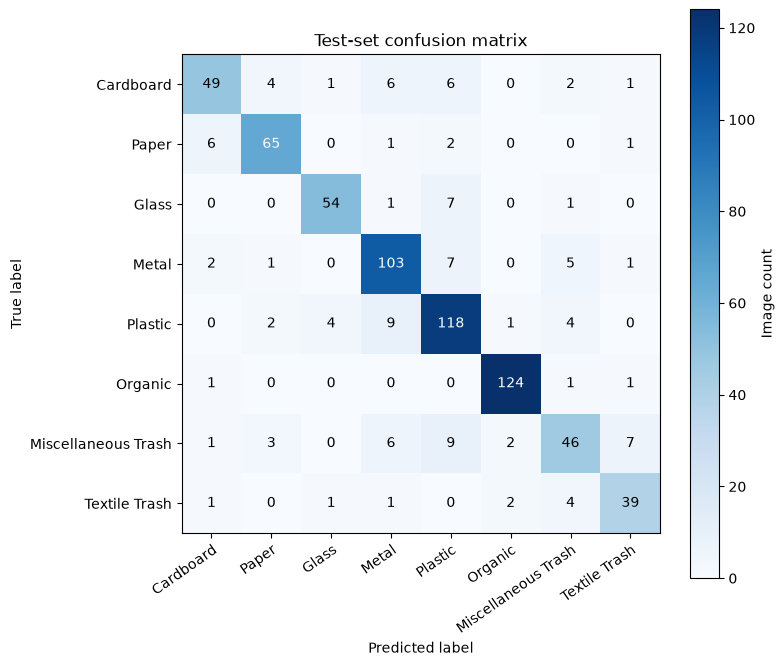

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_features, test_targets = cache_features(test_loader)
model.classifier.eval()
with torch.inference_mode():
    y_pred = model.classifier(test_features).argmax(1).cpu().numpy()
y_true = test_targets.cpu().numpy()
accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {accuracy:.4f}")
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, zero_division=0, digits=3))
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax, label="Image count")
ax.set(xticks=range(len(CLASS_NAMES)), yticks=range(len(CLASS_NAMES)),
       xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
       xlabel="Predicted label", ylabel="True label", title="Test-set confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
threshold = cm.max() / 2 if cm.size else 0
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(col, row, str(cm[row, col]), ha="center", va="center",
                color="white" if cm[row, col] > threshold else "black")
fig.tight_layout()
plt.show()


## 7. Result Analysis

Use the measured test accuracy, per-class F1 scores, and confusion matrix to identify strengths and common confusions. Real-world performance may vary with lighting, camera angle, and waste items not represented in the dataset.

All nine source folders contribute to the eight classes. A random split can place similar scenes in both training and test sets, so performance on new cameras or facilities may be lower. The classifier predicts one category and can struggle with multiple or overlapping items.


In [5]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(len(CLASS_NAMES))), zero_division=0
)
print(f"Overall test accuracy: {accuracy:.1%} ({sum(np.array(y_true) == np.array(y_pred))}/{len(y_true)} correct)")
print(f"Macro-average F1: {np.mean(f1):.3f}")
best_class = int(np.argmax(f1))
worst_class = int(np.argmin(f1))
print(f"Highest class F1: {CLASS_NAMES[best_class]} ({f1[best_class]:.3f})")
print(f"Lowest class F1: {CLASS_NAMES[worst_class]} ({f1[worst_class]:.3f})")
confusions = [(int(cm[r, c]), CLASS_NAMES[r], CLASS_NAMES[c])
              for r in range(len(CLASS_NAMES)) for c in range(len(CLASS_NAMES)) if r != c and cm[r, c] > 0]
confusions.sort(reverse=True)
print("Most common class confusions:")
if confusions:
    for count, actual, predicted in confusions[:5]:
        print(f"  {actual} predicted as {predicted}: {count}")
else:
    print("  No misclassifications on this test split.")

Overall test accuracy: 83.9% (598/713 correct)
Macro-average F1: 0.825
Highest class F1: Organic (0.969)
Lowest class F1: Miscellaneous Trash (0.672)
Most common class confusions:
  Plastic predicted as Metal: 9
  Miscellaneous Trash predicted as Plastic: 9
  Miscellaneous Trash predicted as Textile Trash: 7
  Metal predicted as Plastic: 7
  Glass predicted as Plastic: 7


## 8. Conclusion

The project prepares the full dataset, trains an eight-class CNN, evaluates it on held-out images, and demonstrates dataset and webcam predictions. Run all cells to produce the actual evaluation results.

## 9. Future Scope

- Collect more varied labeled examples, especially for less common categories.
- Test on images from independent facilities and cameras.
- Compare transfer-learning models and tune augmentation using validation data.
- Consider object detection for scenes with multiple waste items.

## 10. Demonstration

The cell below predicts a held-out dataset image, then streams the webcam view with a live class and confidence overlay. Center one item inside the scanner box; interrupt the cell to stop the camera. Enable camera access in Windows.


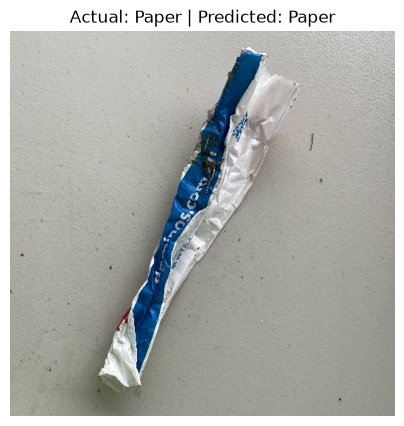

Dataset image predictions: [('Paper', 0.2880314290523529), ('Textile Trash', 0.24654170870780945), ('Cardboard', 0.22212421894073486)]


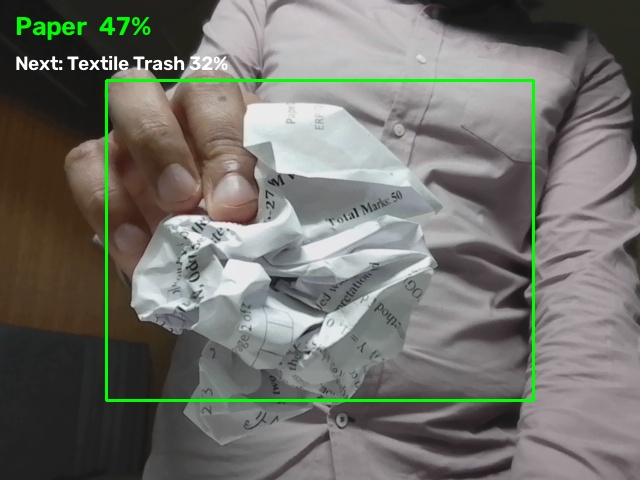

Scanner stopped.
Webcam released.


In [6]:
import torch.nn.functional as F
import cv2
from IPython.display import display, Image as NotebookImage


def predict_image(image_or_path):
    if isinstance(image_or_path, (str, Path)):
        image_path = Path(image_or_path)
        if not image_path.is_file():
            raise FileNotFoundError(f"Image not found: {image_path}")
        with Image.open(image_path) as source:
            image = source.convert("RGB").copy()
    else:
        image = image_or_path.convert("RGB")
    model.eval()
    with torch.inference_mode():
        logits = model.classifier(extract_model_features(eval_transform(image).unsqueeze(0).to(DEVICE)))
        probabilities = F.softmax(logits, dim=1)[0]
    scores, indices = probabilities.topk(3)
    return image, [(CLASS_NAMES[int(index)], float(score)) for score, index in zip(scores, indices)]


sample_index = int(test_indices[0])
sample_path, actual_index = base_dataset.samples[sample_index]
sample_image, sample_predictions = predict_image(sample_path)
plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.axis("off")
plt.title(f"Actual: {CLASS_NAMES[actual_index]} | Predicted: {sample_predictions[0][0]}")
plt.show()
print("Dataset image predictions:", sample_predictions)


def capture_from_webcam(camera_index=0, predict_every=5):
    camera = cv2.VideoCapture(camera_index, cv2.CAP_DSHOW)
    if not camera.isOpened():
        camera.release()
        camera = cv2.VideoCapture(camera_index)
    if not camera.isOpened():
        camera.release()
        raise RuntimeError("Cannot open webcam. Check Windows camera permission or try camera_index=1.")

    prediction_text = "Scanning..."
    predictions = []
    frame_count = 0
    preview = None
    try:
        while True:
            ok, frame = camera.read()
            if not ok:
                raise RuntimeError("Webcam opened but could not provide a frame.")
            height, width = frame.shape[:2]
            x1, x2 = width // 6, width * 5 // 6
            y1, y2 = height // 6, height * 5 // 6
            if frame_count % predict_every == 0:
                roi = cv2.cvtColor(frame[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)
                _, predictions = predict_image(Image.fromarray(roi))
                prediction_text = f"{predictions[0][0]}  {predictions[0][1]:.0%}"

            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, prediction_text, (15, 35), cv2.FONT_HERSHEY_SIMPLEX,
                        0.9, (0, 255, 0), 2, cv2.LINE_AA)
            if len(predictions) > 1:
                second = f"Next: {predictions[1][0]} {predictions[1][1]:.0%}"
                cv2.putText(frame, second, (15, 70), cv2.FONT_HERSHEY_SIMPLEX,
                            0.65, (255, 255, 255), 2, cv2.LINE_AA)
            ok, encoded = cv2.imencode(".jpg", frame)
            if ok:
                image = NotebookImage(data=encoded.tobytes())
                if preview is None:
                    preview = display(image, display_id=True)
                else:
                    preview.update(image)
            frame_count += 1
    except KeyboardInterrupt:
        print("Scanner stopped.")
    finally:
        camera.release()
        cv2.destroyAllWindows()
        print("Webcam released.")


capture_from_webcam()
